# Insurance Fraud Detection using Machine Learning

## Objective
The objective of this project is to identify fraudulent insurance claims using machine learning algorithms. Different classification models are trained and compared to select the best-performing model.

In [1]:
import	pandas	as	pd
import	numpy	as	np
import	matplotlib.pyplot	as	plt
import	seaborn	as	sns
import	warnings
warnings.filterwarnings('ignore')

In [2]:

df=pd.read_csv("insurance_claims.csv")
# Display the first five rows of the dataset
df.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


In [3]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

In [4]:
df.replace('?',	np.nan,	inplace	=	True)

In [5]:
df.isna().sum()

months_as_customer                0
age                               0
policy_number                     0
policy_bind_date                  0
policy_state                      0
policy_csl                        0
policy_deductable                 0
policy_annual_premium             0
umbrella_limit                    0
insured_zip                       0
insured_sex                       0
insured_education_level           0
insured_occupation                0
insured_hobbies                   0
insured_relationship              0
capital-gains                     0
capital-loss                      0
incident_date                     0
incident_type                     0
collision_type                  178
incident_severity                 0
authorities_contacted            91
incident_state                    0
incident_city                     0
incident_location                 0
incident_hour_of_the_day          0
number_of_vehicles_involved       0
property_damage             

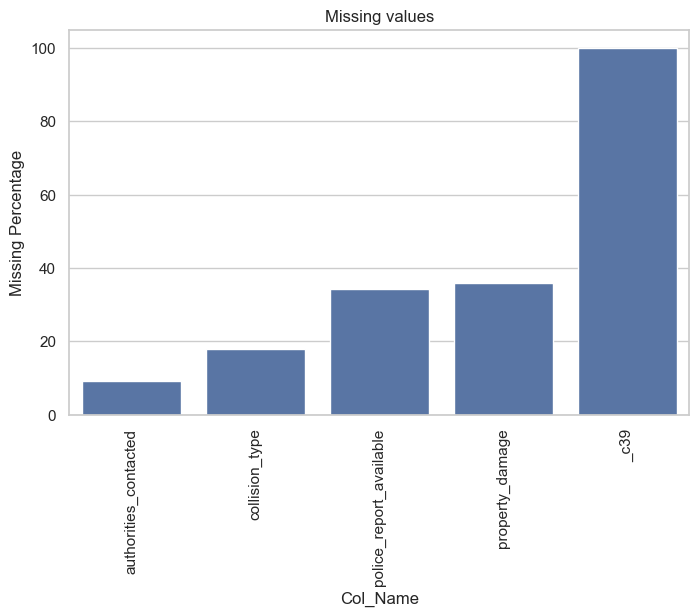

In [6]:
missing=(df.isnull().sum() / len(df))*100
missing=missing[missing>0]
missing.sort_values(inplace=True)
missing=missing.reset_index()
missing.columns=['Col_Name','Null_Count']
sns.set(style='whitegrid',color_codes=True)
plt.figure(figsize=(8,5))
sns.barplot(x='Col_Name',y='Null_Count',data=missing)
plt.xticks(rotation=90)
plt.ylabel("Missing Percentage")
plt.title("Missing values")
plt.show()


In [7]:
#from	above	map	,	fill	na	values	with	the	most	common	values	in	the	respective	columns
df['authorities_contacted']	=	df['authorities_contacted'].fillna(df['authorities_contacted'].mode()[0])
df['collision_type']	=	df['collision_type'].fillna(df['collision_type'].mode()[0])
df['property_damage']	=	df['property_damage'].fillna(df['property_damage'].mode()[0])
df['police_report_available']	=	df['police_report_available'].fillna(df['police_report_available'].mode()[0])

In [8]:
numeric_columns	=	df.select_dtypes(include=['float64',	'int64']).columns
print("Numeric	columns:",	numeric_columns)

Numeric	columns: Index(['months_as_customer', 'age', 'policy_number', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'insured_zip',
       'capital-gains', 'capital-loss', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'bodily_injuries', 'witnesses',
       'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim',
       'auto_year', '_c39'],
      dtype='object')


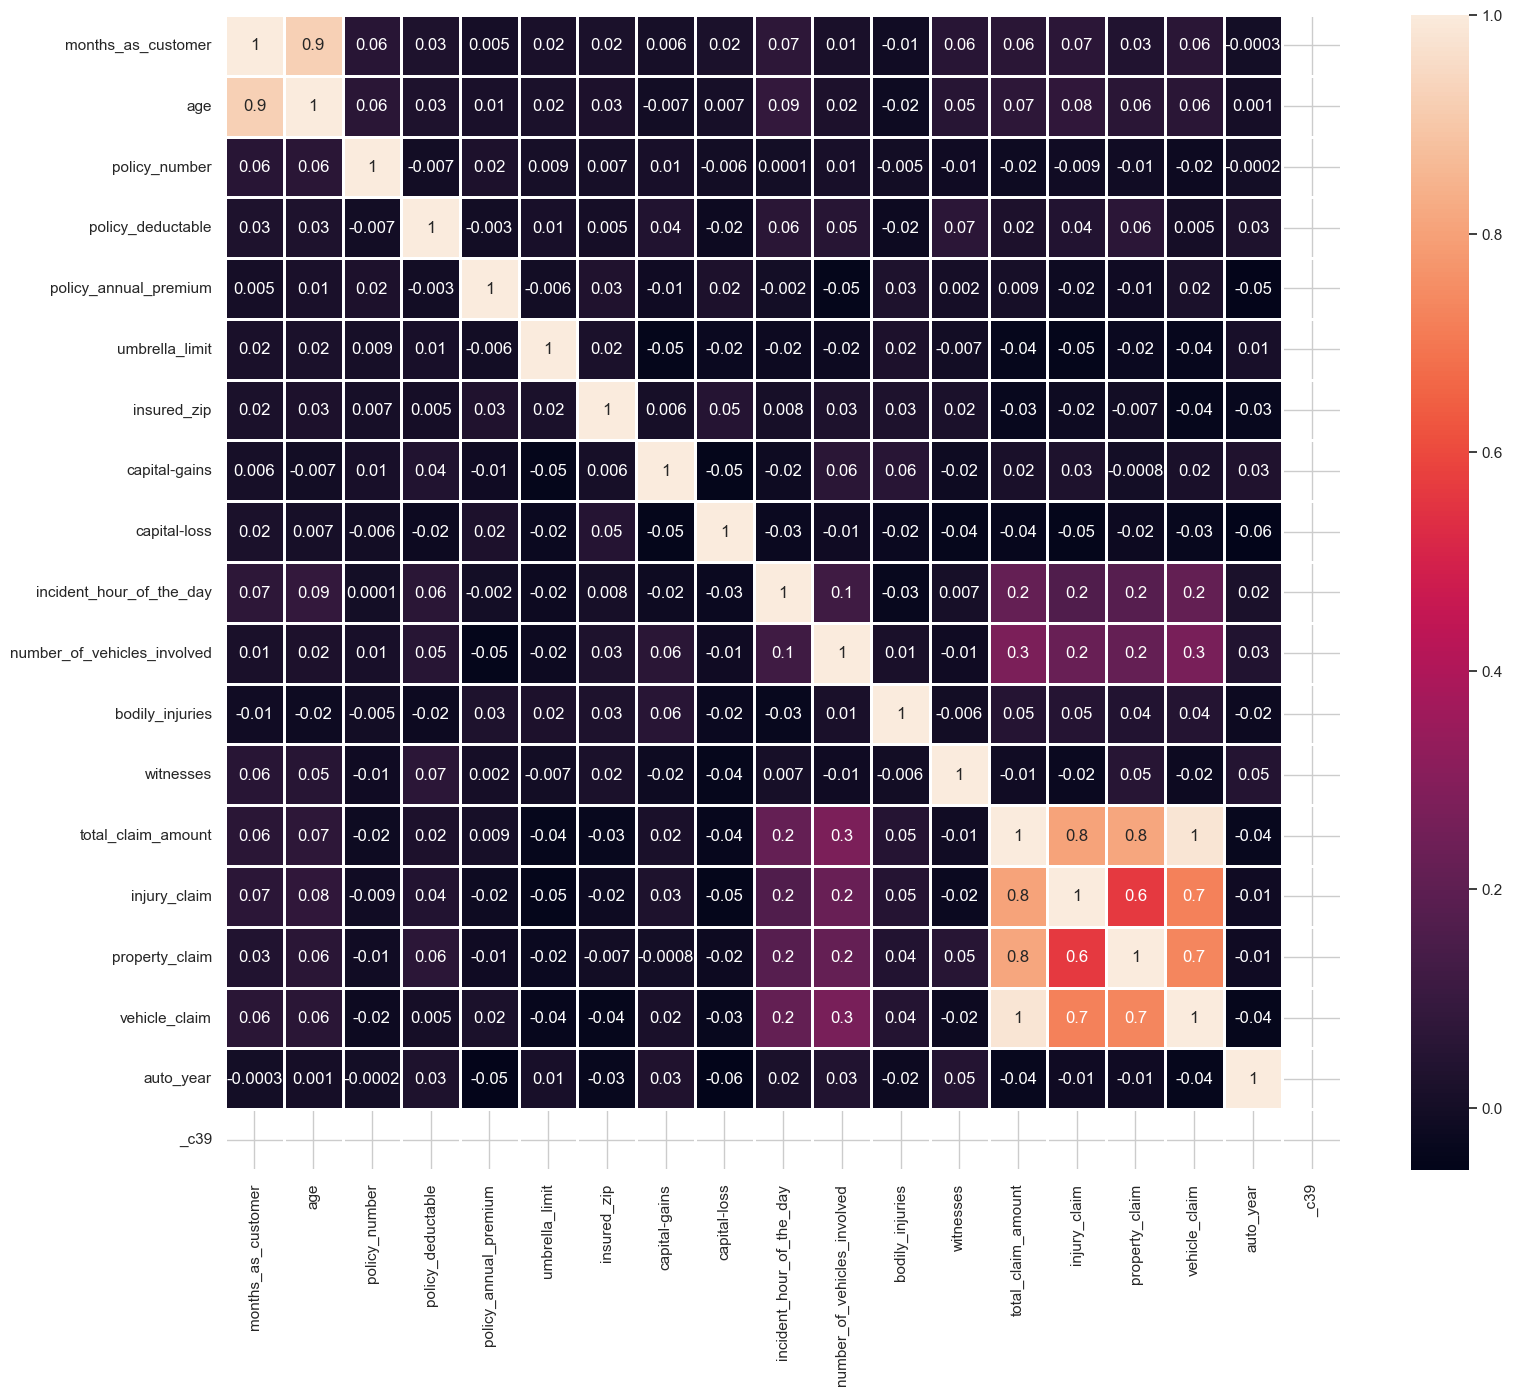

In [9]:
plt.figure(figsize	=	(18,	15))
corr	=	df[numeric_columns].corr()
sns.heatmap(data	=	corr,	annot	=	True,	fmt	=	'.1g',	linewidth	=	2)
plt.show()

In [10]:
categorical_cols	=	df.select_dtypes(include=['object',	'category']).columns
categorical_cols

Index(['policy_bind_date', 'policy_state', 'policy_csl', 'insured_sex',
       'insured_education_level', 'insured_occupation', 'insured_hobbies',
       'insured_relationship', 'incident_date', 'incident_type',
       'collision_type', 'incident_severity', 'authorities_contacted',
       'incident_state', 'incident_city', 'incident_location',
       'property_damage', 'police_report_available', 'auto_make', 'auto_model',
       'fraud_reported'],
      dtype='object')

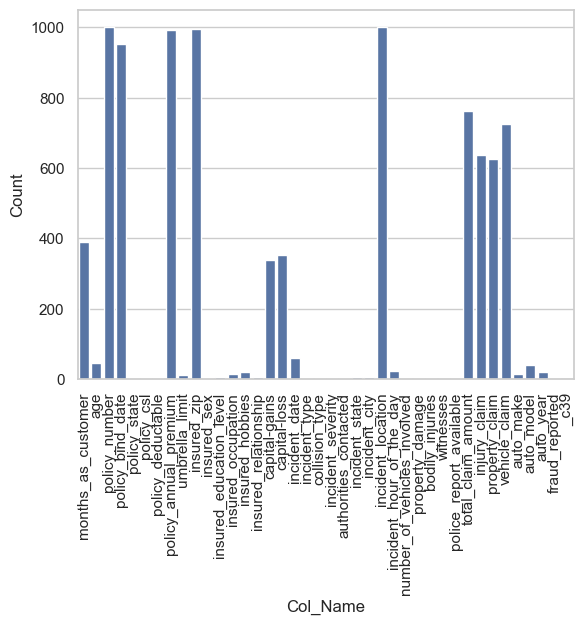

In [11]:
#CREATE	VISULISATION	FOR	NUMBER	OF	DISTINCT	VALUES	IN	EACH	COLUMN
unique	=	df.nunique().to_frame()
unique.columns	=	['Count']
unique.index.names	=	['Col_Name']
unique	=	unique.reset_index()
unique
sns.set(style	=	'whitegrid',	color_codes	=	True)
sns.barplot(x='Col_Name',y='Count',	data	=	unique)
plt.xticks(rotation=90)
plt.show()

In [12]:
unique.sort_values(by	=	'Count',ascending	=	False)

,Col_Name,Count
2,policy_number,1000
24,incident_location,1000
9,insured_zip,995
7,policy_annual_premium,991
3,policy_bind_date,951
31,total_claim_amount,763
34,vehicle_claim,726
32,injury_claim,638
33,property_claim,626
0,months_as_customer,391


In [13]:
#	Drop	the	columns	that	are	categorical	and	high	number	or	repetative	value
#	Drop	Columns	that	are	not	used	in	our	project
to_drop	=	['policy_number','policy_bind_date','policy_state','insured_zip','incident_location','incident_date',
'incident_state','incident_city','insured_hobbies','auto_make','auto_model','auto_year',	'_c39']
df.drop(to_drop,	inplace	=	True,	axis	=	1)
df

Col_Name,months_as_customer,age,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,insured_relationship,...,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,fraud_reported
0,328,48,250/500,1000,1406.91,0,MALE,MD,craft-repair,husband,...,1,YES,1,2,YES,71610,6510,13020,52080,Y
1,228,42,250/500,2000,1197.22,5000000,MALE,MD,machine-op-inspct,other-relative,...,1,NO,0,0,NO,5070,780,780,3510,Y
2,134,29,100/300,2000,1413.14,5000000,FEMALE,PhD,sales,own-child,...,3,NO,2,3,NO,34650,7700,3850,23100,N
3,256,41,250/500,2000,1415.74,6000000,FEMALE,PhD,armed-forces,unmarried,...,1,NO,1,2,NO,63400,6340,6340,50720,Y
4,228,44,500/1000,1000,1583.91,6000000,MALE,Associate,sales,unmarried,...,1,NO,0,1,NO,6500,1300,650,4550,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,3,38,500/1000,1000,1310.80,0,FEMALE,Masters,craft-repair,unmarried,...,1,YES,0,1,NO,87200,17440,8720,61040,N
996,285,41,100/300,1000,1436.79,0,FEMALE,PhD,prof-specialty,wife,...,1,YES,2,3,NO,108480,18080,18080,72320,N
997,130,34,250/500,500,1383.49,3000000,FEMALE,Masters,armed-forces,other-relative,...,3,NO,2,3,YES,67500,7500,7500,52500,N
998,458,62,500/1000,2000,1356.92,5000000,MALE,Associate,handlers-cleaners,wife,...,1,NO,0,1,YES,46980,5220,5220,36540,N


Numeric	columns: Index(['months_as_customer', 'age', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'capital-gains',
       'capital-loss', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'bodily_injuries', 'witnesses',
       'total_claim_amount', 'injury_claim', 'property_claim',
       'vehicle_claim'],
      dtype='object', name='Col_Name')


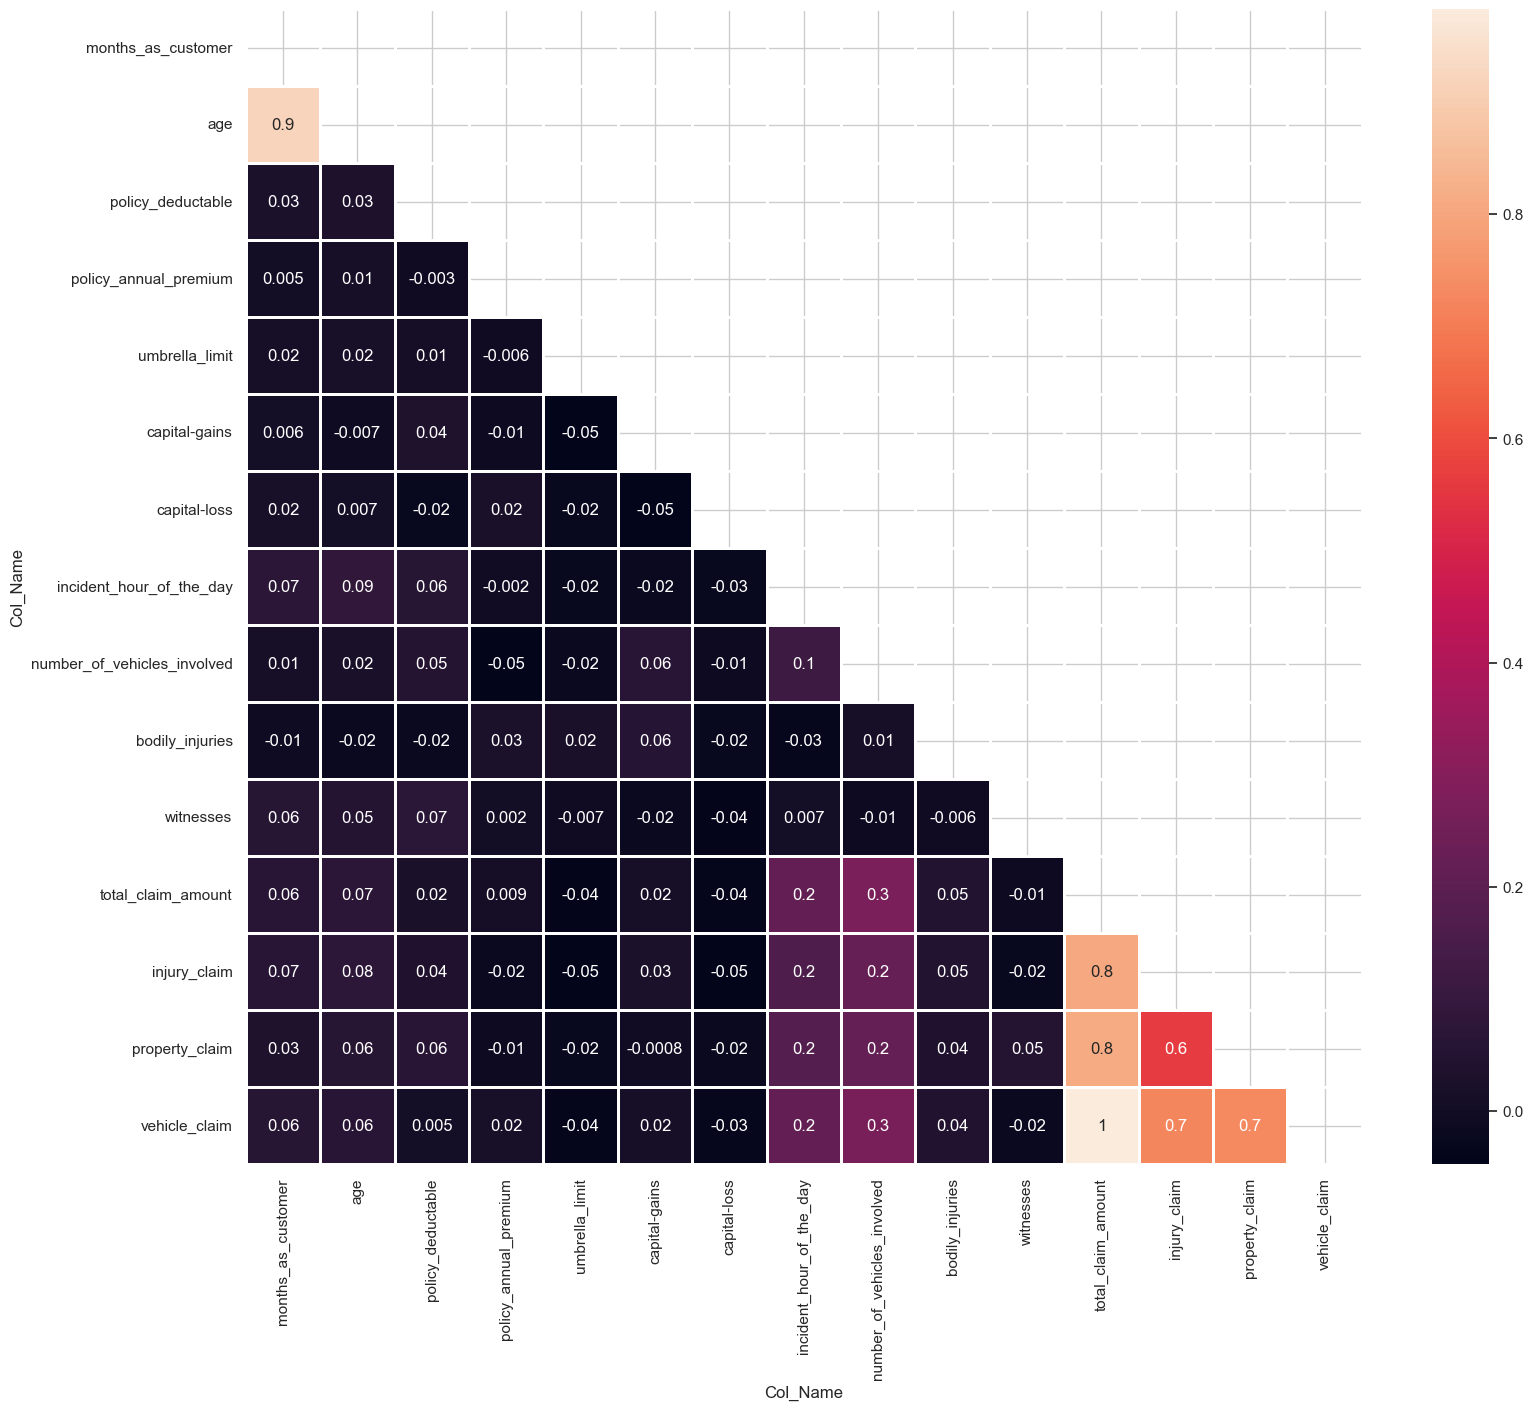

In [14]:
numeric_columns	=	df.select_dtypes(include=['float64',	'int64']).columns
print("Numeric	columns:",	numeric_columns)
plt.figure(figsize	=	(18,	15))
corr	=	df[numeric_columns].corr()
mask	=	np.triu(np.ones_like(corr,	dtype	=	bool))
sns.heatmap(data	=	corr,mask	=	mask,	annot	=	True,	fmt	=	'.1g',	linewidth	=	2)
plt.show()

In [15]:
df.drop(columns=['age','total_claim_amount'],	inplace	=	True,	axis	=	1)
df.head()

Col_Name,months_as_customer,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,insured_relationship,capital-gains,...,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,injury_claim,property_claim,vehicle_claim,fraud_reported
0,328,250/500,1000,1406.91,0,MALE,MD,craft-repair,husband,53300,...,5,1,YES,1,2,YES,6510,13020,52080,Y
1,228,250/500,2000,1197.22,5000000,MALE,MD,machine-op-inspct,other-relative,0,...,8,1,NO,0,0,NO,780,780,3510,Y
2,134,100/300,2000,1413.14,5000000,FEMALE,PhD,sales,own-child,35100,...,7,3,NO,2,3,NO,7700,3850,23100,N
3,256,250/500,2000,1415.74,6000000,FEMALE,PhD,armed-forces,unmarried,48900,...,5,1,NO,1,2,NO,6340,6340,50720,Y
4,228,500/1000,1000,1583.91,6000000,MALE,Associate,sales,unmarried,66000,...,20,1,NO,0,1,NO,1300,650,4550,N


In [16]:
#	GET	THE	VARIABLES	AND	TARGET	SEPARATED	AS	DIFFERENT	DATAFRAME
x	=	df.drop('fraud_reported',	axis=1)	#variables
y	=	df['fraud_reported']	#target
y

0      Y
1      Y
2      N
3      Y
4      N
      ..
995    N
996    N
997    N
998    N
999    N
Name: fraud_reported, Length: 1000, dtype: object

In [17]:
#	now	converting	categorical	columns	into	numerical	using	one-encoding
categorical_col	=	x.select_dtypes(include	=	['object'])
categorical_col	=	pd.get_dummies(categorical_col,	drop_first	=	True,dtype	=	int)
categorical_col

,policy_csl_250/500,policy_csl_500/1000,insured_sex_MALE,insured_education_level_College,insured_education_level_High School,insured_education_level_JD,insured_education_level_MD,insured_education_level_Masters,insured_education_level_PhD,insured_occupation_armed-forces,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
0,1,0,1,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,1,1,1
1,1,0,1,0,0,0,1,0,0,0,...,1,0,1,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,1,0,...,1,0,1,0,0,0,0,1,0,0
3,1,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,0
4,0,1,1,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,1,0,0,0,0,0,1,0,0,...,0,0,1,0,0,1,0,0,1,0
996,0,0,0,0,0,0,0,0,1,0,...,1,0,0,0,0,1,0,0,1,0
997,1,0,0,0,0,0,0,1,0,1,...,0,1,1,0,0,0,0,1,0,1
998,0,1,1,0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,1


In [18]:
#now	concate	the	numerical_col	and	categorical_col	in	our	variables	data	frame		(x)
numerical_col	=	x.select_dtypes(include	=	['int64'])
x	=	pd.concat([numerical_col,	categorical_col],	axis	=	1)
numerical_col.columns

Index(['months_as_customer', 'policy_deductable', 'umbrella_limit',
       'capital-gains', 'capital-loss', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'bodily_injuries', 'witnesses',
       'injury_claim', 'property_claim', 'vehicle_claim'],
      dtype='object', name='Col_Name')

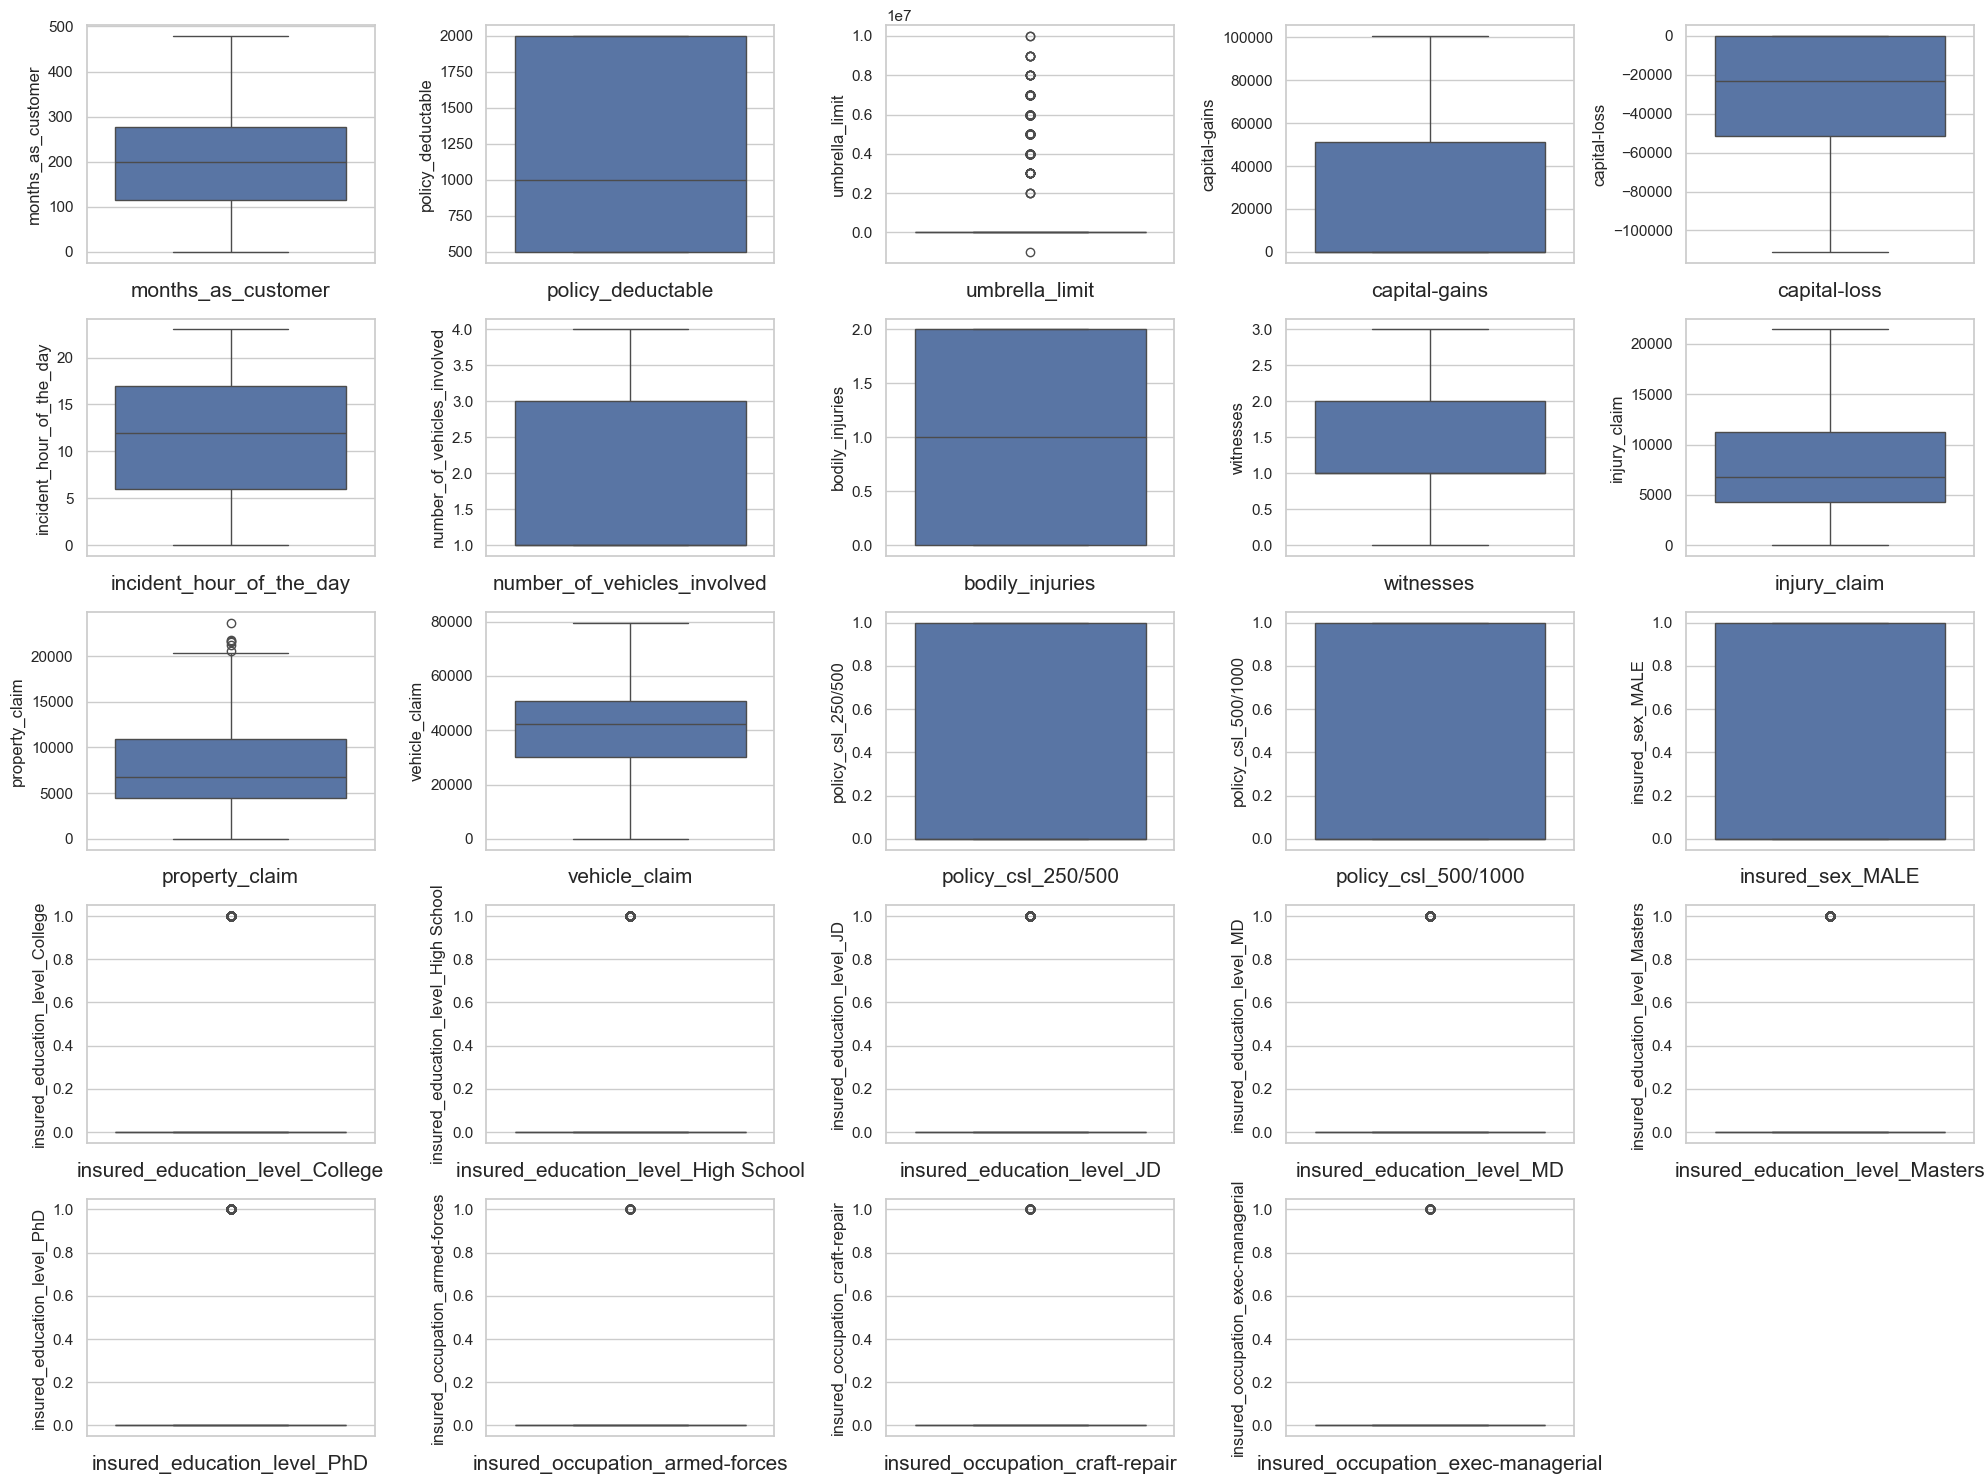

In [19]:
#	Outlier	Check
plt.figure(figsize	=	(20,	15))
plotnumber	=	1
for	col	in	x.columns:
    if	plotnumber<=24:
        ax	=	plt.subplot(5,	5,	plotnumber)
        sns.boxplot(x[col])
        plt.xlabel(col,	fontsize	=	15)
    plotnumber	+=	1
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [21]:
x_train

,months_as_customer,policy_deductable,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
887,441,500,4000000,24000,-50500,4,1,0,0,640,...,1,0,1,0,0,0,0,1,0,0
317,275,2000,0,39400,-63900,8,3,1,1,5360,...,0,1,0,1,0,0,0,0,1,0
796,421,500,4000000,49500,-81100,7,1,2,3,16860,...,1,0,0,0,0,0,0,0,0,0
425,4,500,0,0,0,0,4,0,0,6080,...,0,1,0,0,0,0,0,1,0,0
991,257,1000,0,59400,-32200,21,1,0,1,0,...,1,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678,276,500,0,44500,-61400,11,3,0,2,13860,...,0,0,1,0,0,1,0,0,0,0
789,169,500,0,0,-57600,0,1,0,0,7740,...,1,0,1,0,0,1,0,0,0,1
240,249,1000,0,0,0,16,1,0,0,5350,...,0,0,0,0,0,1,0,0,0,1
263,244,2000,7000000,0,-45000,5,3,1,1,5590,...,0,1,1,0,0,0,0,1,0,0


In [22]:
x_test

,months_as_customer,policy_deductable,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
908,285,2000,0,52600,0,3,1,1,0,500,...,1,0,1,0,0,0,0,1,1,0
973,230,1000,0,0,-51500,15,1,2,3,9820,...,1,0,0,0,0,0,0,0,1,0
154,101,1000,7000000,52000,-44500,20,3,1,3,9040,...,1,0,1,0,0,0,0,0,0,0
977,266,500,4000000,0,-49600,18,3,1,1,4440,...,0,1,0,0,0,0,0,0,0,0
50,430,2000,7000000,0,0,19,3,0,3,16360,...,0,0,1,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
617,103,500,0,66300,0,14,2,2,2,4060,...,0,0,1,0,0,0,0,1,0,0
694,73,500,0,0,0,15,3,0,0,0,...,1,0,0,1,0,0,1,0,0,1
181,426,2000,0,29600,-22300,13,1,2,3,16800,...,0,1,1,0,0,0,0,1,1,0
421,147,1000,0,0,0,22,1,1,0,13520,...,0,0,0,1,0,0,0,0,0,0


In [23]:
#Numerical	columns	only	required	be	STANDARISE
numerical_data	=	x_train[['months_as_customer',	'policy_deductable',	'umbrella_limit',
							'capital-gains',	'capital-loss',	'incident_hour_of_the_day',
							'number_of_vehicles_involved',	'bodily_injuries',	'witnesses',
							'injury_claim',	'property_claim',	'vehicle_claim']]

In [24]:
#STANDARDIZATION
from	sklearn.preprocessing	import	StandardScaler
scaler	=	StandardScaler()
scaled_data	=	scaler.fit_transform(numerical_data)

In [25]:
scaled_df_num	=	pd.DataFrame(data	=	scaled_data,	
                                 columns	=	numerical_data.columns,
                                 index	=	x_train.index)
scaled_df_num.head()

,months_as_customer,policy_deductable,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,property_claim,vehicle_claim
887,2.074615,-1.041729,1.295503,-0.019577,-0.859126,-1.096975,-0.821792,-1.202225,-1.349038,-1.361866,-1.367596,-1.676726
317,0.621501,1.378552,-0.477641,0.537069,-1.338801,-0.517236,1.140697,0.006041,-0.443643,-0.407244,0.694777,0.557802
796,1.899541,-1.041729,1.295503,0.902142,-1.954505,-0.662171,-0.821792,1.214308,1.367146,1.918636,0.226242,1.552769
425,-1.750750,-1.041729,-0.477641,-0.887078,0.948608,-1.676714,2.121941,-1.202225,-1.349038,-0.261624,0.989402,0.578531
991,0.463935,-0.234969,-0.477641,1.259986,-0.204046,1.366916,-0.821792,-1.202225,-0.443643,-1.491306,-0.430526,0.222001


In [26]:
x_train.drop(columns=scaled_df_num.columns,inplace=True)
x_train = pd.concat([scaled_df_num, x_train], axis=1)

In [27]:
# Scale the numerical columns in the test data
scaled_test = scaler.transform(x_test[numerical_data.columns])

scaled_test = pd.DataFrame(
    scaled_test,
    columns=numerical_data.columns,
    index=x_test.index
)

# Remove the original numerical columns
x_test.drop(columns=numerical_data.columns, inplace=True)

# Add the scaled numerical columns back
x_test = pd.concat([scaled_test, x_test], axis=1)


In [28]:
# ==========================================
# Apply SMOTE on Training Data
# ==========================================

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

x_train, y_train = smote.fit_resample(x_train, y_train)

print(y_train.value_counts())

fraud_reported
N    602
Y    602
Name: count, dtype: int64


In [29]:
x_train.head()

,months_as_customer,policy_deductable,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
0,2.074615,-1.041729,1.295503,-0.019577,-0.859126,-1.096975,-0.821792,-1.202225,-1.349038,-1.361866,...,1,0,1,0,0,0,0,1,0,0
1,0.621501,1.378552,-0.477641,0.537069,-1.338801,-0.517236,1.140697,0.006041,-0.443643,-0.407244,...,0,1,0,1,0,0,0,0,1,0
2,1.899541,-1.041729,1.295503,0.902142,-1.954505,-0.662171,-0.821792,1.214308,1.367146,1.918636,...,1,0,0,0,0,0,0,0,0,0
3,-1.750750,-1.041729,-0.477641,-0.887078,0.948608,-1.676714,2.121941,-1.202225,-1.349038,-0.261624,...,0,1,0,0,0,0,0,1,0,0
4,0.463935,-0.234969,-0.477641,1.259986,-0.204046,1.366916,-0.821792,-1.202225,-0.443643,-1.491306,...,1,0,0,1,0,0,1,0,0,0


In [30]:
#SUPPORT	VECTOR	CLASSIFIER
from	sklearn.svm	import	SVC
from	sklearn.metrics	import	accuracy_score,	confusion_matrix,	classification_report
svc_model	=	SVC()
svc_model.fit(x_train,y_train)
y_pred	=	svc_model.predict(x_test)


In [31]:
svc_model_train_acc	=	accuracy_score(y_train,	svc_model.predict(x_train))
svc_model_test_acc	=	accuracy_score(y_test,	y_pred)
print("Training	Accuracy:	",svc_model_train_acc)
print("Testing	Accuracy:	",	svc_model_test_acc)
print(confusion_matrix(y_test,	y_pred))
print(classification_report(y_test,	y_pred))

Training	Accuracy:	 0.9534883720930233
Testing	Accuracy:	 0.795
[[140  11]
 [ 30  19]]
              precision    recall  f1-score   support

           N       0.82      0.93      0.87       151
           Y       0.63      0.39      0.48        49

    accuracy                           0.80       200
   macro avg       0.73      0.66      0.68       200
weighted avg       0.78      0.80      0.78       200



In [32]:
# logistic regressiom

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(x_train, y_train)
y_pred = logistic_model.predict(x_test)

In [34]:
logistic_train_acc = accuracy_score(
    y_train,
    logistic_model.predict(x_train)
)

logistic_test_acc = accuracy_score(
    y_test,
    y_pred
)

print("Training Accuracy:", logistic_train_acc)
print("Testing Accuracy:", logistic_test_acc)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Training Accuracy: 0.8654485049833887
Testing Accuracy: 0.82
[[135  16]
 [ 20  29]]
              precision    recall  f1-score   support

           N       0.87      0.89      0.88       151
           Y       0.64      0.59      0.62        49

    accuracy                           0.82       200
   macro avg       0.76      0.74      0.75       200
weighted avg       0.82      0.82      0.82       200



In [35]:
#K-NEAREST-NEIGHBORS

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

scores = {}
for k in range(1, 31, 2):
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(x_train, y_train)
    scores[k] = accuracy_score(y_test, m.predict(x_test))

best_k = max(scores, key=scores.get)
print("Best k:", best_k, "| accuracy:", scores[best_k])

knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(x_train, y_train)
y_pred = knn_model.predict(x_test)

Best k: 1 | accuracy: 0.505


In [37]:
knn_model_train_acc	=	accuracy_score(y_train,	knn_model.predict(x_train))
knn_model_test_acc	=	accuracy_score(y_test,	y_pred)
print("Training	Accuracy:",knn_model_train_acc)
print("Testing	Accuracy:",	knn_model_test_acc)
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Training	Accuracy: 1.0
Testing	Accuracy: 0.505
[[68 83]
 [16 33]]
              precision    recall  f1-score   support

           N       0.81      0.45      0.58       151
           Y       0.28      0.67      0.40        49

    accuracy                           0.51       200
   macro avg       0.55      0.56      0.49       200
weighted avg       0.68      0.51      0.53       200



In [38]:
#DECISION	TREE	CLASSIFIER

In [39]:
from	sklearn.tree	import	DecisionTreeClassifier
decision_tree_model	=	DecisionTreeClassifier()
decision_tree_model.fit(x_train,y_train)
y_pred	=	decision_tree_model.predict(x_test)


In [40]:
decision_tree_model_train_acc	=	accuracy_score(y_train,	decision_tree_model.predict(x_train))
decision_tree_model_test_acc	=	accuracy_score(y_test,	y_pred)
print("Training	Accuracy:	",decision_tree_model_train_acc)
print("Testing	Accuracy:	",	decision_tree_model_test_acc)
print(confusion_matrix(y_test,	y_pred))
print(classification_report(y_test,	y_pred))


Training	Accuracy:	 1.0
Testing	Accuracy:	 0.74
[[120  31]
 [ 21  28]]
              precision    recall  f1-score   support

           N       0.85      0.79      0.82       151
           Y       0.47      0.57      0.52        49

    accuracy                           0.74       200
   macro avg       0.66      0.68      0.67       200
weighted avg       0.76      0.74      0.75       200



In [41]:
from	sklearn.model_selection	import	GridSearchCV
grid_params	=	{
'criterion'	:	['gini',	'entropy'],
'max_depth'	:	[3,	5,	7,	10],
'min_samples_split'	:	range(2,	10,	1),
'min_samples_leaf'	:	range(2,	10,	1)
}
150
50
200
200
200
grid_search	=	GridSearchCV(decision_tree_model,grid_params,cv	=5,n_jobs=1,verbose	=	1)
grid_search.fit(x_train,	y_train)

Fitting 5 folds for each of 512 candidates, totalling 2560 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': range(2, 10), 'min_samples_split': range(2, 10)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_example

In [42]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 9}
0.8355809128630705


In [43]:
decision_tree_model	=	grid_search.best_estimator_
y_pred	=	decision_tree_model.predict(x_test)

In [44]:
from	sklearn.metrics	import	accuracy_score,	confusion_matrix,	classification_report
decision_tree_model_train_acc	=	accuracy_score(y_train,	decision_tree_model.predict(x_train))
decision_tree_model_test_acc	=	accuracy_score(y_test,	y_pred)
print(f"Training	accuracy	of	Decision	Tree	is	:	{decision_tree_model_train_acc}")
print(f"Test	accuracy	of	Decision	Tree	is	:	{decision_tree_model_test_acc}")
print(confusion_matrix(y_test,	y_pred))
print(classification_report(y_test,	y_pred))

Training	accuracy	of	Decision	Tree	is	:	0.867109634551495
Test	accuracy	of	Decision	Tree	is	:	0.765
[[120  31]
 [ 16  33]]
              precision    recall  f1-score   support

           N       0.88      0.79      0.84       151
           Y       0.52      0.67      0.58        49

    accuracy                           0.77       200
   macro avg       0.70      0.73      0.71       200
weighted avg       0.79      0.77      0.77       200



In [45]:
## Random	Forest	Classifier

In [46]:
from	sklearn.ensemble	import	RandomForestClassifier
rf_model=RandomForestClassifier(criterion='entropy',max_depth=15,max_features='sqrt',min_samples_leaf=1
,min_samples_split=2,random_state=42)
rf_model.fit(x_train,	y_train)
y_pred	=	rf_model.predict(x_test)

In [47]:
# ==========================================
# Hyperparameter Tuning - Random Forest
# ==========================================
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

rf = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'criterion': ['gini', 'entropy'], 'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also

In [48]:
print(random_search.best_params_)

{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'gini'}


In [49]:
print(random_search.best_score_)

0.8630152143845089


In [50]:
best_rf = random_search.best_estimator_

best_rf.fit(x_train, y_train)

rf_pred = best_rf.predict(x_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.79


In [51]:
## feature immportance
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                           Feature  Importance
44  incident_severity_Minor Damage    0.114883
45    incident_severity_Total Loss    0.095580
11                   vehicle_claim    0.061270
10                  property_claim    0.057035
5         incident_hour_of_the_day    0.047444
0               months_as_customer    0.047037
9                     injury_claim    0.046272
8                        witnesses    0.037804
3                    capital-gains    0.032203
4                     capital-loss    0.032163


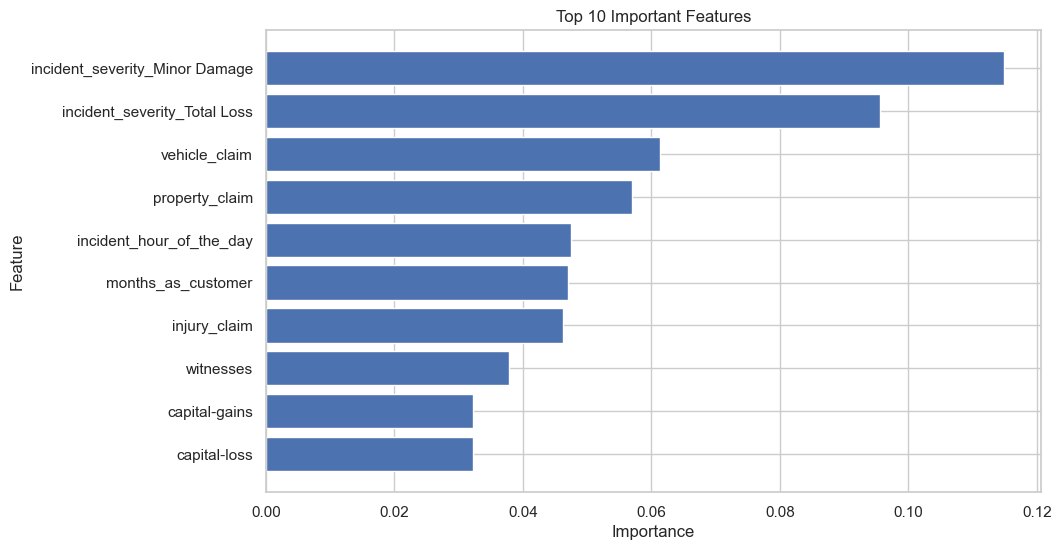

In [52]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Feature'][:10],
    feature_importance['Importance'][:10]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()



In [53]:
# ==========================================
# Classification Report
# ==========================================

from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           N       0.83      0.91      0.87       151
           Y       0.60      0.43      0.50        49

    accuracy                           0.79       200
   macro avg       0.72      0.67      0.68       200
weighted avg       0.77      0.79      0.78       200



In [54]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

print(cm)

[[137  14]
 [ 28  21]]


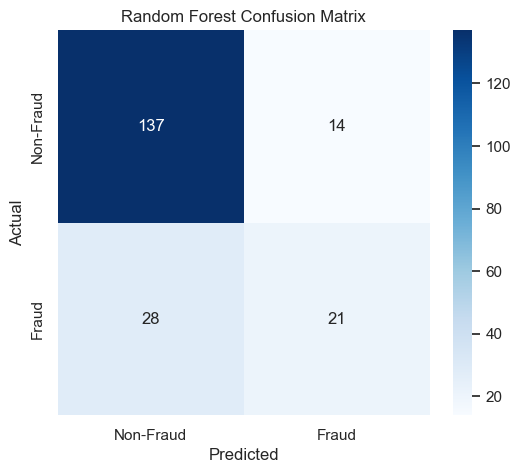

In [55]:

# ==========================================
# Confusion Matrix Heatmap
# ==========================================

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Fraud','Fraud'],
    yticklabels=['Non-Fraud','Fraud']
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [56]:
# ==========================================
# ROC Curve and AUC Score
# ==========================================

from sklearn.metrics import roc_curve, roc_auc_score

# Probability of the positive class (Fraud)
rf_prob = best_rf.predict_proba(x_test)[:,1]

# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, rf_prob, pos_label='Y')

# Calculate AUC Score
auc_score = roc_auc_score(y_test, rf_prob)

print("AUC Score:", auc_score)

AUC Score: 0.7911879983781593


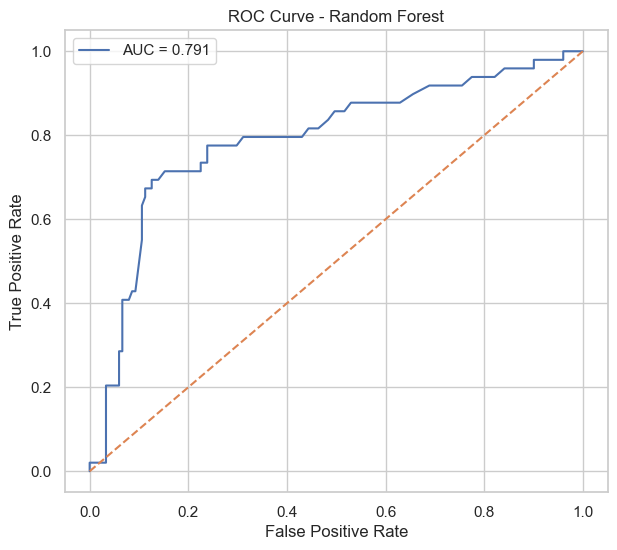

In [57]:
# ==========================================
# Plot ROC Curve
# ==========================================

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest")

plt.legend()

plt.show()

In [58]:
from	sklearn.metrics	import	accuracy_score,	confusion_matrix,	classification_report
rf_model_train_acc	=	accuracy_score(y_train,	rf_model.predict(x_train))
rf_model_test_acc	=	accuracy_score(y_test,	y_pred)
print("Training	accuracy:	",	rf_model_train_acc)
print("Test	accuracy:	",	rf_model_test_acc)
print(confusion_matrix(y_test,	y_pred))
print(classification_report(y_test,	y_pred))

Training	accuracy:	 1.0
Test	accuracy:	 0.81
[[133  18]
 [ 20  29]]
              precision    recall  f1-score   support

           N       0.87      0.88      0.88       151
           Y       0.62      0.59      0.60        49

    accuracy                           0.81       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.81      0.81      0.81       200



In [59]:
##	Gradient	Boosting	Classifier##

In [60]:
from	sklearn.ensemble	import	GradientBoostingClassifier
gb	=	GradientBoostingClassifier()
gb.fit(x_train,	y_train)
#	accuracy	score,	confusion	matrix	and	classification	report	of	gradient	boosting	classifier
gb_acc	=	accuracy_score(y_test,	gb.predict(x_test))
print(f"Training	Accuracy	of	Gradient	Boosting	Classifier	is	{accuracy_score(y_train,	gb.predict(x_train))}")
print(f"Test	Accuracy	of	Gradient	Boosting	Classifier	is	{gb_acc}	\n")
print(f"Confusion	Matrix	:-	\n{confusion_matrix(y_test,	gb.predict(x_test))}\n")
print(f"Classification	Report	:-	\n	{classification_report(y_test,	gb.predict(x_test))}")

Training	Accuracy	of	Gradient	Boosting	Classifier	is	0.936046511627907
Test	Accuracy	of	Gradient	Boosting	Classifier	is	0.82	

Confusion	Matrix	:-	
[[133  18]
 [ 18  31]]

Classification	Report	:-	
	              precision    recall  f1-score   support

           N       0.88      0.88      0.88       151
           Y       0.63      0.63      0.63        49

    accuracy                           0.82       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.82      0.82      0.82       200



In [61]:
# ==========================================
# ROC-AUC for all models (Fraud = 'Y' is the positive class)
# ==========================================
from sklearn.metrics import roc_curve, roc_auc_score
import pandas as pd

# Convert the target to 0/1 so every model is scored the same way
y_test_bin = (y_test == 'Y').astype(int)

def fraud_score(model, X):
    """Return a fraud score for class 'Y' (works with or without predict_proba)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, list(model.classes_).index('Y')]
    return model.decision_function(X)   # SVC without probability=True

all_models = {
    'SVC': svc_model,
    'KNN': knn_model,
    'Decision Tree (tuned)': decision_tree_model,
    'Random Forest (tuned)': best_rf,
    'Gradient Boosting': gb,
    'Logistic Regression': logistic_model
}

auc_results = []
roc_data = {}

for name, model in all_models.items():
    scores = fraud_score(model, x_test)
    fpr, tpr, _ = roc_curve(y_test_bin, scores)
    auc = roc_auc_score(y_test_bin, scores)
    roc_data[name] = (fpr, tpr, auc)
    auc_results.append({'Model': name, 'ROC-AUC': round(auc, 4)})

auc_df = pd.DataFrame(auc_results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
auc_df

,Model,ROC-AUC
0,Random Forest (tuned),0.7912
1,SVC,0.7825
2,Gradient Boosting,0.7748
3,Logistic Regression,0.7631
4,Decision Tree (tuned),0.7373
5,KNN,0.5619


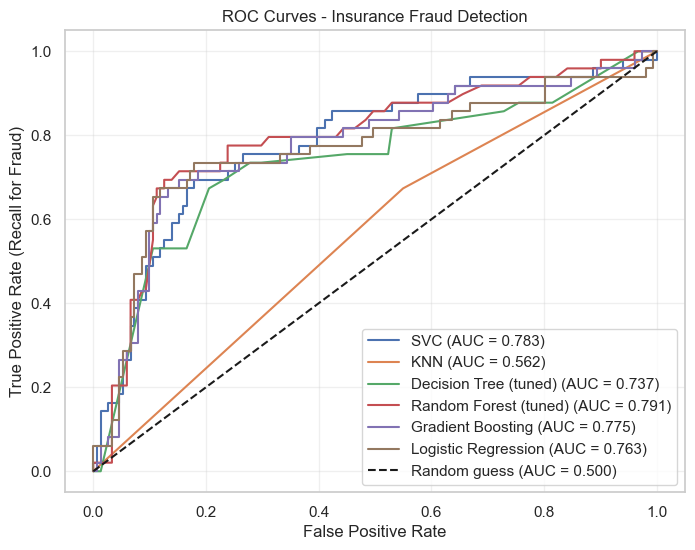

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall for Fraud)')
plt.title('ROC Curves - Insurance Fraud Detection')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

In [69]:
# ==========================================
# Precision, Recall, F1 for the Fraud class ('Y') - all models
# ==========================================
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

metric_rows = []

for name, model in all_models.items():
    pred = model.predict(x_test)
    metric_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (Y)': precision_score(y_test, pred, pos_label='Y', zero_division=0),
        'Recall (Y)': recall_score(y_test, pred, pos_label='Y', zero_division=0),
        'F1 (Y)': f1_score(y_test, pred, pos_label='Y', zero_division=0)
    })

metrics_df = pd.DataFrame(metric_rows).sort_values('F1 (Y)', ascending=False).reset_index(drop=True)
metrics_df.round(3)

,Model,Accuracy,Precision (Y),Recall (Y),F1 (Y)
0,Gradient Boosting,0.820,0.633,0.633,0.633
1,Logistic Regression,0.820,0.644,0.592,0.617
2,Decision Tree (tuned),0.765,0.516,0.673,0.584
3,Random Forest (tuned),0.790,0.600,0.429,0.500
4,SVC,0.795,0.633,0.388,0.481
5,KNN,0.505,0.284,0.673,0.400


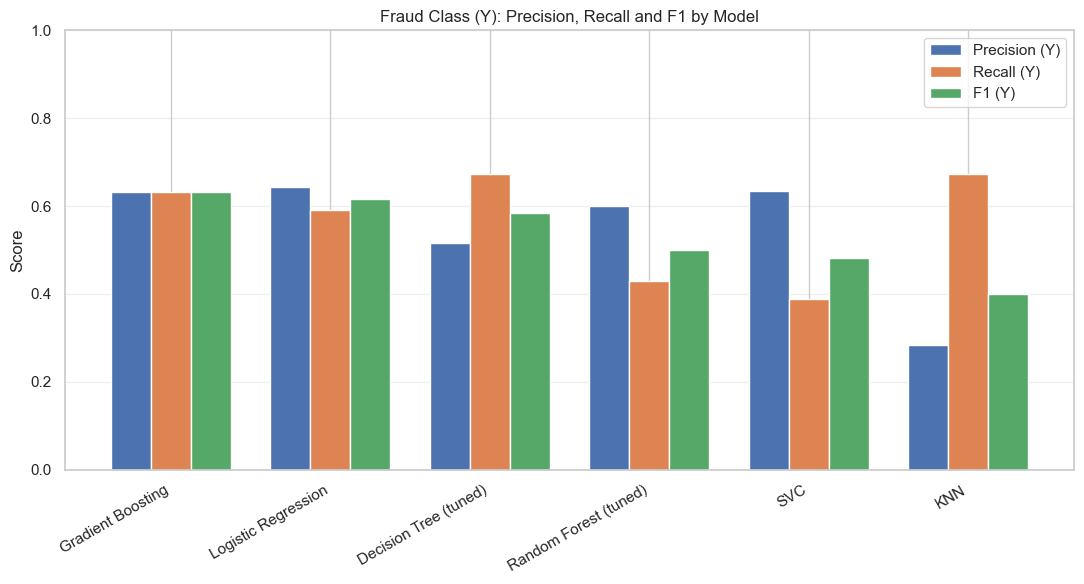

In [70]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = metrics_df.set_index('Model')[['Precision (Y)', 'Recall (Y)', 'F1 (Y)']]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(11, 6))
plt.bar(x - width, plot_df['Precision (Y)'], width, label='Precision (Y)')
plt.bar(x,          plot_df['Recall (Y)'],    width, label='Recall (Y)')
plt.bar(x + width,  plot_df['F1 (Y)'],        width, label='F1 (Y)')

plt.xticks(x, plot_df.index, rotation=30, ha='right')
plt.ylim(0, 1)
plt.ylabel('Score')
plt.title('Fraud Class (Y): Precision, Recall and F1 by Model')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
##	Models	Comparison

In [64]:
## Models Comparison
models = pd.DataFrame({
    'Model': ['SVC', 'KNN', 'Decision Tree', 'Random Forest (tuned)', 'Gradient Boost', 'Logistic Regression'],
    'Score': [svc_model_test_acc,
              knn_model_test_acc,
              decision_tree_model_test_acc,
              rf_accuracy,
              gb_acc,
              logistic_test_acc]
})
models.sort_values(by='Score', ascending=False)

,Model,Score
4,Gradient Boost,0.820
5,Logistic Regression,0.820
0,SVC,0.795
3,Random Forest (tuned),0.790
2,Decision Tree,0.765
1,KNN,0.505


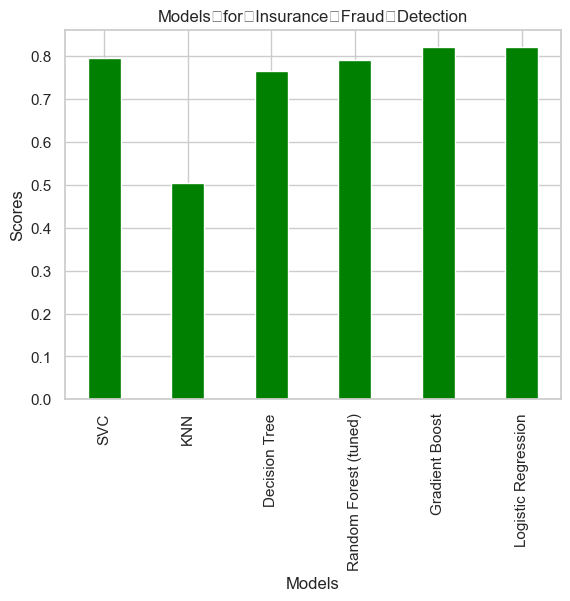

In [65]:
plt.bar(models['Model'],models['Score'],	width=0.4,	color='green')
plt.xlabel("Models")
plt.xticks(rotation=90)
plt.ylabel("Scores")
plt.title("Models	for	Insurance	Fraud	Detection")
plt.show()
	

In [66]:
# ==========================================
# Save the Trained Random Forest Model
# ==========================================

import joblib

joblib.dump(best_rf, "insurance_fraud_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [67]:
# ==========================================
# Load the Saved Model
# ==========================================

loaded_model = joblib.load("insurance_fraud_model.pkl")

print("Model Loaded Successfully")

Model Loaded Successfully


In [68]:
# ==========================================
# Test the Loaded Model
# ==========================================

prediction = loaded_model.predict(x_test)

print("Accuracy of Loaded Model:", accuracy_score(y_test, prediction))

Accuracy of Loaded Model: 0.79


# Conclusion

This project developed a machine learning pipeline to detect fraudulent insurance claims from historical claims data. The raw dataset contained 40
columns, including identifier fields (policy_number, insured_zip), high-cardinality categorical fields (auto_model, insured_hobbies),
and a fully empty artifact column (_c39). After removing 15 non-predictive or redundant columns, guided by cardinality analysis and 
a correlation heatmap, 24 features remained for modeling. Missing values in collision_type, authorities_contacted,
property_damage, and police_report_available were imputed using the mode. Categorical variables were one-hot encoded,
numerical features were standardized, and SMOTE was applied to the training set only to address the class imbalance between fraudulent (25%) and 
legitimate (75%) claims.

Six classification algorithms (Logistic Regression, Support Vector Machine, K-Nearest Neighbors, Decision Tree,
Random Forest, and Gradient Boosting) were trained and evaluated on accuracy, precision, recall, F1-score (fraud class), and ROC-AUC.

| Model | Accuracy | Precision (Fraud) | Recall (Fraud) | F1 (Fraud) | ROC-AUC |
|---|---|---|---|---|---|
| Gradient Boosting | 0.82 | 0.63 | 0.63 | 0.63 | 0.775 |
| Logistic Regression | 0.82 | 0.64 | 0.59 | 0.62 | 0.763 |
| Random Forest (tuned) | 0.79 | 0.62 | 0.59 | 0.60 | 0.791 |
| Decision Tree (tuned) | 0.765 | 0.52 | 0.67 | 0.58 | 0.737 |
| SVC | 0.795 | 0.63 | 0.39 | 0.48 | 0.783 |
| KNN (tuned) | 0.505 | 0.28 | 0.67 | 0.40 | 0.562 |

**Overall performance.** Gradient Boosting and Logistic Regression tied for the highest accuracy (82%).
Gradient Boosting gave the most balanced fraud detection (precision and recall both 0.63, F1 = 0.63),
while Logistic Regression was very close (precision 0.64, recall 0.59) despite being a far simpler linear model.
This suggests that model complexity alone does not guarantee better performance on this dataset.

**ROC-AUC.** Random Forest (0.791), SVC (0.783), Gradient Boosting (0.775), and Logistic Regression (0.763) showed similar ability to separate fraudulent from genuine claims,
while the tuned Decision Tree (0.737) was weaker. The ranking by AUC differs slightly from the ranking by accuracy, which is why both measures were reported.
Feature importance from the tuned Random Forest identified incident_severity, vehicle_claim, and property_claim as the strongest predictors of fraud, giving a degree of interpretability useful for claims review.

**SVC.** SVC ranked claims well (AUC = 0.783) but had low fraud recall (0.39) at the default 0.5 threshold,
so it missed many fraudulent claims. This suggests its decision threshold, rather than its ranking ability, is the main weakness.

**KNN.** KNN performed sharply worse (accuracy 50.5%, AUC 0.562, only slightly above random guessing) even after tuning k.
The optimal k was 1, which memorizes individual training points rather than generalizing. This indicates that distance-based methods are poorly suited to this high-dimensional,
one-hot-encoded feature space.
 
Despite the strong results from Gradient Boosting and Logistic Regression, recall on the fraud class remains the key limitation across all models: 
a meaningful share of fraudulent claims still go undetected. This reflects the broader difficulty of fraud detection on imbalanced data, 
where false negatives carry real financial cost. Future work could explore class-weighted loss functions as an alternative to SMOTE,
threshold tuning to prioritize recall over raw accuracy, and richer feature engineering from the currently-dropped date and location fields.

Overall, this project shows that both a simple linear model (Logistic Regression) and a properly tuned ensemble model (Gradient Boosting) 
can meaningfully support insurance fraud detection, with the choice between them coming down to a trade-off between interpretability and 
marginal recall gains — helping insurers flag high-risk claims for investigator review and reduce losses from undetected fraud.